In [ ]:
!pip install -q kagglehub librosa soundfile tensorflow scikit-learn \
    matplotlib seaborn pandas numpy openai-whisper gradio gTTS

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 12.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 4.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 1.16.1 which is incompatible.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 1.16.1 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you ha

In [ ]:
%pip install --upgrade "huggingface-hub>=1.31.0,<2.0.0" "click>=8.2.1,<9.0.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 8.5 MB/s eta 0:00:00
  Attempting uninstall: click
    Found existing installation: click 8.1.8
    Uninstalling click-8.1.8:
      Successfully uninstalled click-8.1.8
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.16.1
    Uninstalling huggingface_hub-1.16.1:
      Successfully uninstalled huggingface_hub-1.16.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.0 which is incompatible.


In [ ]:
!apt-get -qq update
!apt-get -qq install -y ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "uwrfkaggler/ravdess-emotional-speech-audio"
)

print("Path to dataset files:", path)

# Inspect the downloaded dataset
for root, dirs, files in os.walk(path):
    if files:
        print("Folder:", root)
        print("Number of files:", len(files))
        print("Sample files:", files[:5])
        break

Using Colab cache for faster access to the 'ravdess-emotional-speech-audio' dataset.
Path to dataset files: /kaggle/input/ravdess-emotional-speech-audio
Folder: /kaggle/input/ravdess-emotional-speech-audio/Actor_02
Number of files: 60
Sample files: ['03-01-08-01-01-01-02.wav', '03-01-01-01-01-01-02.wav', '03-01-07-02-01-02-02.wav', '03-01-07-01-01-02-02.wav', '03-01-01-01-02-01-02.wav']


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

SAMPLE_RATE = 22050
DURATION = 4
N_MFCC = 40
MAX_LEN = 174

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [ ]:
audio_files = glob.glob(
    os.path.join(path, "**", "*.wav"),
    recursive=True
)

print("Total WAV files found:", len(audio_files))

# Emotion ID to emotion name
emotion_map = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

records = []

for file in audio_files:
    filename = os.path.basename(file)
    parts = filename.replace(".wav", "").split("-")

    if len(parts) != 7:
        continue

    emotion_id = parts[2]
    statement_id = parts[4]
    actor_id = parts[6]

    if emotion_id in emotion_map:
        records.append({
            "file": file,
            "emotion": emotion_map[emotion_id],
            "emotion_id": emotion_id,
            "statement_id": statement_id,
            "actor_id": int(actor_id)
        })

df = pd.DataFrame(records)

print("Valid audio files:", len(df))
print("\nEmotion distribution:")
print(df["emotion"].value_counts())

print("\nSample records:")
display(df.head())

Total WAV files found: 2880
Valid audio files: 2880

Emotion distribution:
emotion
surprised    384
disgust      384
fearful      384
sad          384
happy        384
calm         384
angry        384
neutral      192
Name: count, dtype: int64

Sample records:


,file,emotion,emotion_id,statement_id,actor_id
0,/kaggle/input/ravdess-emotional-speech-audio/A...,surprised,08,01,2
1,/kaggle/input/ravdess-emotional-speech-audio/A...,neutral,01,01,2
2,/kaggle/input/ravdess-emotional-speech-audio/A...,disgust,07,01,2
3,/kaggle/input/ravdess-emotional-speech-audio/A...,disgust,07,01,2
4,/kaggle/input/ravdess-emotional-speech-audio/A...,neutral,01,02,2


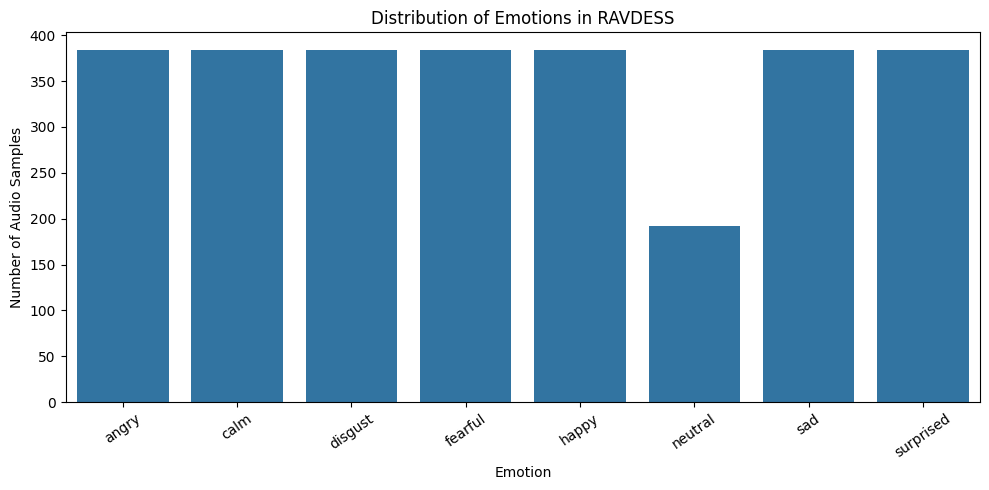

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="emotion",
    order=sorted(df["emotion"].unique())
)

plt.title("Distribution of Emotions in RAVDESS")
plt.xlabel("Emotion")
plt.ylabel("Number of Audio Samples")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [ ]:
def extract_mfcc(file_path):
    try:
        audio, sr = librosa.load(
            file_path,
            sr=SAMPLE_RATE,
            duration=DURATION,
            mono=True
        )

        target_length = SAMPLE_RATE * DURATION

        # Pad short recordings or truncate long recordings
        if len(audio) < target_length:
            audio = np.pad(
                audio,
                (0, target_length - len(audio))
            )
        else:
            audio = audio[:target_length]

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=N_MFCC,
            n_fft=2048,
            hop_length=512
        )

        # Ensure every sample has the same number of frames
        if mfcc.shape[1] < MAX_LEN:
            mfcc = np.pad(
                mfcc,
                ((0, 0), (0, MAX_LEN - mfcc.shape[1]))
            )
        else:
            mfcc = mfcc[:, :MAX_LEN]

        return mfcc.astype(np.float32)

    except Exception as e:
        print("Error processing:", file_path, e)
        return None


X_list = []
valid_rows = []

for _, row in df.iterrows():
    features = extract_mfcc(row["file"])

    if features is not None:
        X_list.append(features)
        valid_rows.append(row)

df = pd.DataFrame(valid_rows).reset_index(drop=True)

X = np.array(X_list, dtype=np.float32)
y = df["emotion"].values
groups = df["actor_id"].values

# CNN expects height, width, and channel dimensions
X = X[..., np.newaxis]

print("Feature tensor shape:", X.shape)
print("Labels shape:", y.shape)

Feature tensor shape: (2880, 40, 174, 1)
Labels shape: (2880,)


In [ ]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# First: reserve test actors
splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

trainval_idx, test_idx = next(
    splitter1.split(X, y_encoded, groups)
)

# Second: reserve validation actors from remaining actors
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_rel, val_rel = next(
    splitter2.split(
        X[trainval_idx],
        y_encoded[trainval_idx],
        groups[trainval_idx]
    )
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

X_train, y_train = X[train_idx], y_encoded[train_idx]
X_val, y_val = X[val_idx], y_encoded[val_idx]
X_test, y_test = X[test_idx], y_encoded[test_idx]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("Training actors:", sorted(set(groups[train_idx])))
print("Validation actors:", sorted(set(groups[val_idx])))
print("Testing actors:", sorted(set(groups[test_idx])))

assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))

Training samples: 1800
Validation samples: 480
Testing samples: 600
Training actors: [np.int64(4), np.int64(5), np.int64(6), np.int64(8), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Validation actors: [np.int64(2), np.int64(3), np.int64(7), np.int64(15)]
Testing actors: [np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]


In [ ]:
num_classes = len(encoder.classes_)

model = Sequential([
    Input(shape=(N_MFCC, MAX_LEN, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 174, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 174, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 87, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 43, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 43, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 13440)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,720,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,815,048 (6.92 MB)

 Trainable params: 1,814,600 (6.92 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model = Sequential([
    Input(shape=(N_MFCC, MAX_LEN, 1)),

    Conv2D(32, (3, 3), padding="same",
           activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.20),

    Conv2D(64, (3, 3), padding="same",
           activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), padding="same",
           activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.40),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

model.save("/content/speech_emotion_cnn.keras")
print("Best model saved.")

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 471ms/step - accuracy: 0.2328 - loss: 2.1541 - val_accuracy: 0.1375 - val_loss: 2.9006 - learning_rate: 0.0010
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 504ms/step - accuracy: 0.3133 - loss: 1.9393 - val_accuracy: 0.1583 - val_loss: 2.2333 - learning_rate: 0.0010
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 42s 517ms/step - accuracy: 0.3633 - loss: 1.7895 - val_accuracy: 0.2167 - val_loss: 2.0508 - learning_rate: 0.0010
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 501ms/step - accuracy: 0.4228 - loss: 1.6649 - val_accuracy: 0.3750 - val_loss: 1.8614 - learning_rate: 0.0010
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 490ms/step - accuracy: 0.4889 - loss: 1.5567 - val_accuracy: 0.4417 - val_loss: 1.8125 - learning_rate: 0.0010
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 512ms/step - accuracy: 0.5250 - loss: 1.4222 - val_accuracy: 0.4208 - val_loss: 1.7556 - learning_rate: 0.0010
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 28s 492ms/step - accuracy: 0.5556 - loss: 1.

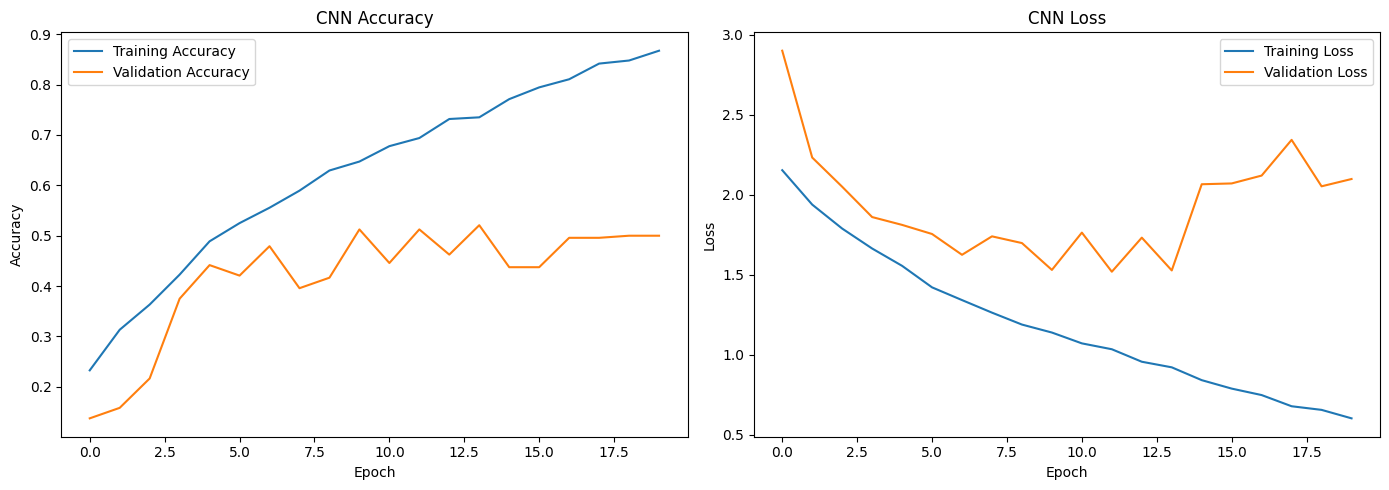

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(num_classes),
        target_names=encoder.classes_,
        zero_division=0
    )
)

Test Accuracy: 43.33%

Classification Report:
              precision    recall  f1-score   support

       angry       0.89      0.42      0.58        80
        calm       0.35      0.88      0.50        80
     disgust       0.50      0.53      0.51        80
     fearful       0.31      0.80      0.45        80
       happy       1.00      0.07      0.14        80
     neutral       0.50      0.10      0.17        40
         sad       0.00      0.00      0.00        80
   surprised       0.67      0.50      0.57        80

    accuracy                           0.43       600
   macro avg       0.53      0.41      0.36       600
weighted avg       0.53      0.43      0.38       600



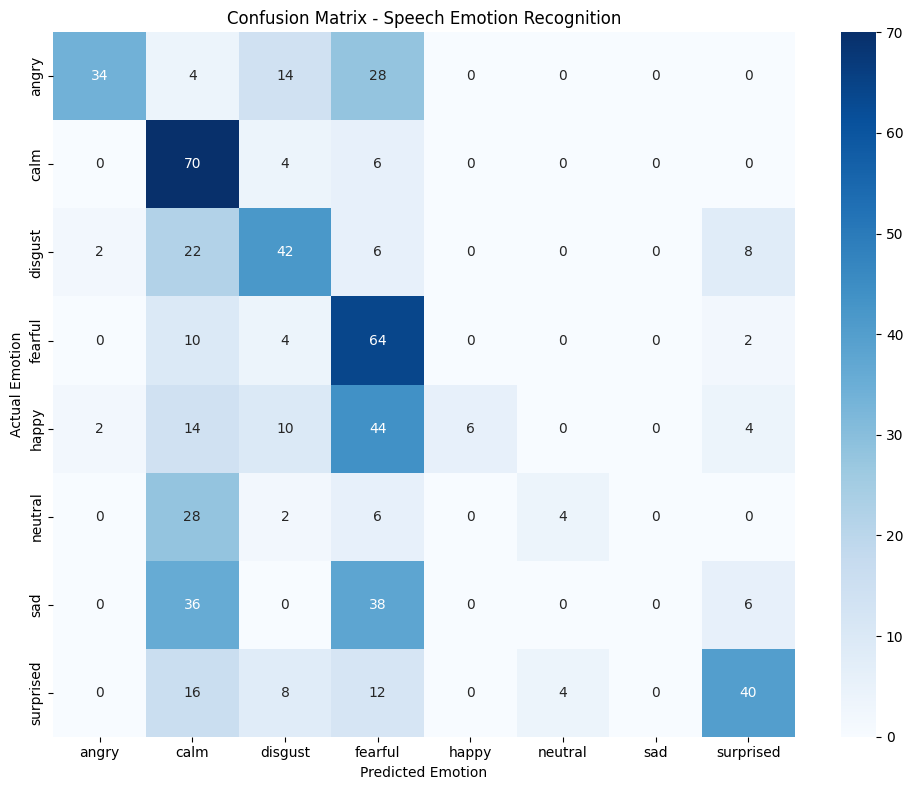

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("Confusion Matrix - Speech Emotion Recognition")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

In [ ]:
import pickle

with open("/content/label_encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)

print("Saved model and label encoder.")

Saved model and label encoder.


In [ ]:
def predict_emotion(audio_path):
    features = extract_mfcc(audio_path)

    if features is None:
        raise ValueError("Could not process the audio file.")

    features = features[np.newaxis, ..., np.newaxis]

    probabilities = model.predict(features, verbose=0)[0]
    predicted_index = np.argmax(probabilities)

    emotion = encoder.inverse_transform([predicted_index])[0]
    confidence = float(probabilities[predicted_index])

    return emotion, confidence


# Test with one dataset audio file
sample_path = df.iloc[0]["file"]

emotion, confidence = predict_emotion(sample_path)

print("Audio file:", os.path.basename(sample_path))
print("Predicted emotion:", emotion)
print(f"Model confidence: {confidence * 100:.2f}%")

Audio file: 03-01-08-01-01-01-02.wav
Predicted emotion: surprised
Model confidence: 78.91%


In [ ]:
import whisper

stt_model = whisper.load_model("base")

def speech_to_text(audio_path):
    result = stt_model.transcribe(
        audio_path,
        language="en",
        fp16=False
    )

    return result["text"].strip()


transcript = speech_to_text(sample_path)

print("Recognized speech:")
print(transcript)

100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 119MiB/s]


Recognized speech:
Kids are talking by the door.


In [ ]:
from gtts import gTTS
import tempfile

def text_to_speech(text):
    tts = gTTS(text=text, lang="en")

    temp_file = tempfile.NamedTemporaryFile(
        suffix=".mp3",
        delete=False
    )

    temp_file.close()
    tts.save(temp_file.name)

    return temp_file.name


response_text = (
    f"The recognized speech is: {transcript}. "
    f"The detected emotion is {emotion}."
)

speech_file = text_to_speech(response_text)

print("Generated speech file:", speech_file)

Generated speech file: /tmp/tmpfjuw064c.mp3


In [ ]:
from IPython.display import Audio, display

display(Audio(speech_file))

In [ ]:
!pip install -q jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.8 MB/s eta 0:00:00


In [ ]:
from jiwer import wer

reference_statements = {
    "01": "Kids are talking by the door",
    "02": "Dogs are sitting by the door"
}

test_df = df.iloc[test_idx].reset_index(drop=True)

references = []
hypotheses = []

for _, row in test_df.head(10).iterrows():
    reference = reference_statements.get(row["statement_id"])

    if reference is None:
        continue

    hypothesis = speech_to_text(row["file"])

    references.append(reference)
    hypotheses.append(hypothesis)

    print("Reference:", reference)
    print("Predicted:", hypothesis)
    print("-" * 50)

if references:
    stt_wer = wer(references, hypotheses)
    print(f"Word Error Rate (WER): {stt_wer * 100:.2f}%")
else:
    print("No reference transcripts were available.")

Reference: Dogs are sitting by the door
Predicted: Dogs are sitting by the door.
--------------------------------------------------
Reference: Kids are talking by the door
Predicted: Kids are talking by the door.
--------------------------------------------------
Reference: Kids are talking by the door
Predicted: Kids are talking by the door.
--------------------------------------------------
Reference: Kids are talking by the door
Predicted: Kids are talking by the door.
--------------------------------------------------
Reference: Dogs are sitting by the door
Predicted: Dogs are sitting by the door.
--------------------------------------------------
Reference: Dogs are sitting by the door
Predicted: Dogs are sitting by the door.
--------------------------------------------------
Reference: Dogs are sitting by the door
Predicted: The dogs are sitting by the door!
--------------------------------------------------
Reference: Dogs are sitting by the door
Predicted: Dogs are sitting by t

In [ ]:
import gradio as gr
import os

def process_audio(audio_path):
    if audio_path is None:
        return (
            "Please upload or record an audio file.",
            "",
            "",
            None
        )

    try:
        # 1. Speech-to-Text
        transcript = speech_to_text(audio_path)

        # 2. Emotion Classification
        emotion, confidence = predict_emotion(audio_path)

        # 3. Prepare response
        response = (
            f"The detected emotion is {emotion}. "
            f"The model confidence is {confidence * 100:.1f} percent."
        )

        # 4. Text-to-Speech
        output_audio = text_to_speech(response)

        return (
            transcript,
            emotion.capitalize(),
            f"{confidence * 100:.2f}%",
            output_audio
        )

    except Exception as e:
        return (
            f"Processing error: {str(e)}",
            "",
            "",
            None
        )


with gr.Blocks(title="Speech Emotion Recognition") as demo:
    gr.Markdown("# Speech Emotion Recognition System")
    gr.Markdown(
        "Upload or record speech to obtain a transcript, "
        "predicted emotion, and spoken response."
    )
    audio_input = gr.Audio(
        sources=["upload", "microphone"],
        type="filepath",
        label="Upload or Record Speech"
    )

    run_button = gr.Button(
        "Analyze Audio",
        variant="primary"
    )

    transcript_output = gr.Textbox(
        label="Speech-to-Text Transcript"
    )

    emotion_output = gr.Textbox(
        label="Predicted Emotion"
    )

    confidence_output = gr.Textbox(
        label="Prediction Confidence"
    )

    audio_output = gr.Audio(
        label="Text-to-Speech Response",
        type="filepath"
    )

    run_button.click(
        fn=process_audio,
        inputs=[audio_input],
        outputs=[
            transcript_output,
            emotion_output,
            confidence_output,
            audio_output
        ]
    )


demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5eb48c1bfeb2fbf26d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
